In [4]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()
words[:10]

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

In [9]:
# build the dataset

def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


# what we had

In [2]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) 
b1 = torch.randn(n_hidden,                          generator = g)
W2 = torch.randn((n_hidden, vocab_size),            generator = g)
b2 = torch.randn(vocab_size,                        generator = g)
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [6]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      1/ 200000: 27.8817
  10000/ 200000: 2.7073
  20000/ 200000: 2.0407
  30000/ 200000: 2.3638
  40000/ 200000: 2.2808
  50000/ 200000: 2.4303
  60000/ 200000: 1.7856
  70000/ 200000: 1.9982
  80000/ 200000: 2.4749
  90000/ 200000: 2.2837
 100000/ 200000: 1.9924
 110000/ 200000: 2.0996
 120000/ 200000: 2.1612
 130000/ 200000: 2.1826
 140000/ 200000: 1.9403
 150000/ 200000: 2.4570
 160000/ 200000: 2.1866
 170000/ 200000: 1.7776
 180000/ 200000: 1.6747
 190000/ 200000: 2.1325
 200000/ 200000: 2.4201


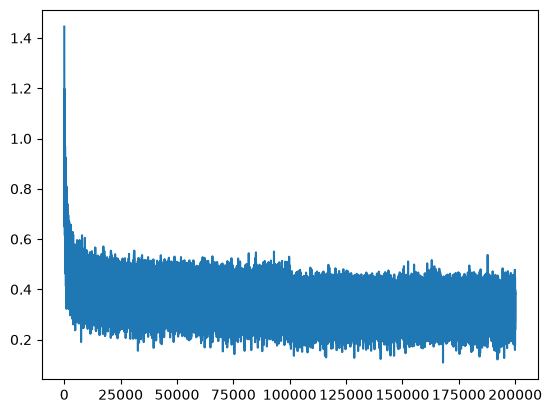

In [7]:
plt.plot(lossi)

In [3]:
@torch.no_grad() # this decorator disables gradient tracking

def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')
    

NameError: name 'Xtr' is not defined

In [9]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size
    while True:
        # forward pass the neural net
        emb = C[torch.tensor([context])] # (1, block_size, n_embd)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1) 
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples = 1, generator = g).item()
        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[ix] for ix in out)) # decode and print the generated word


carlah.
amorie.
khirmin.
rey.
cassanden.
jazhubedah.
sart.
kaeli.
nellara.
chaiir.
kaleigh.
ham.
jore.
quinn.
salin.
alianni.
wazthoniearyxi.
jace.
pirran.
eddeci.


# first issue: great loss function upon initialization

In [ ]:
# expected loss function value upon initialization
-torch.tensor(1/27.0).log()

tensor(3.2958)

which is far from the value we have: about 27

In [ ]:
# 4-dimensional example of the issue
logits = torch.tensor([0.0, 0.0, 0.0, 0.0])
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()
print(logits, probs, loss)

logits = torch.randn(4) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()
print(logits, probs, loss)

tensor([0., 0., 0., 0.]) tensor([0.2500, 0.2500, 0.2500, 0.2500]) tensor(1.3863)
tensor([ -1.9560, -10.5334,   8.2636,  -9.5486]) tensor([3.6448e-05, 6.8637e-09, 9.9996e-01, 1.8376e-08]) tensor(11.7072)


in other words, the problem is that the value of logits upon initialization deviates too much from 0, and we need to change the value of logits upon initialization so that the value is closer to zero. 

Since we want a logits that is close to zero, we scale down the value of W2 and b2: we multiply W2 by 0.01, and set b2 simply to 0. 

The reason why we do not want the value of W2 to be completely zero is that 

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) 
b1 = torch.randn(n_hidden,                          generator = g)
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [ ]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3221
  10000/ 200000: 2.2348
  20000/ 200000: 1.7331
  30000/ 200000: 2.2949
  40000/ 200000: 2.2809
  50000/ 200000: 2.3564
  60000/ 200000: 1.7236
  70000/ 200000: 1.8785
  80000/ 200000: 2.2791
  90000/ 200000: 2.2516
 100000/ 200000: 2.1685
 110000/ 200000: 2.0582
 120000/ 200000: 1.9812
 130000/ 200000: 2.0898
 140000/ 200000: 1.9113
 150000/ 200000: 2.6490
 160000/ 200000: 1.9833
 170000/ 200000: 1.7239
 180000/ 200000: 1.6800
 190000/ 200000: 2.1829
 200000/ 200000: 2.3703


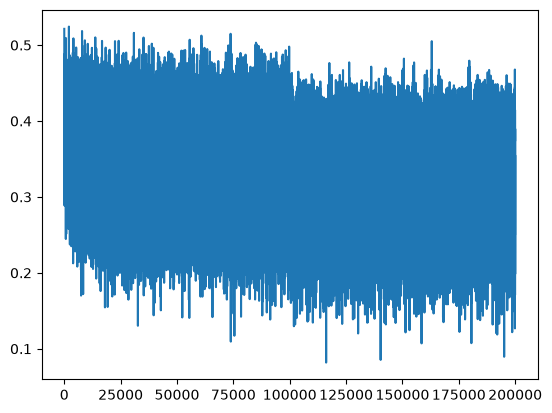

In [ ]:
plt.plot(lossi)

Here you can see the beginning of the graph is not like a hockey stick anymore, which means that the initialization is normal, and we do not get those easy gain at the beginning of the training. 

In [ ]:
split_loss('train')
split_loss('val')

train 2.069589138031006
val 2.131074905395508


# second issue: activation of the hidden layer

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) 
b1 = torch.randn(n_hidden,                          generator = g)
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [ ]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3221


In [ ]:
h

tensor([[ 0.8100, -0.8997, -0.9993,  ..., -0.9097, -1.0000,  1.0000],
        [-1.0000, -0.9571, -0.7145,  ...,  0.4898,  0.9090,  0.9937],
        [ 0.9983, -0.3340,  1.0000,  ...,  0.9443,  0.9905,  1.0000],
        ...,
        [-1.0000,  0.9604, -0.1418,  ..., -0.1266,  1.0000,  1.0000],
        [-1.0000, -0.4385, -0.8882,  ..., -0.3316,  0.9995,  1.0000],
        [-1.0000,  0.9604, -0.1418,  ..., -0.1266,  1.0000,  1.0000]],
       grad_fn=<TanhBackward0>)

(array([2069.,  144.,  106.,   82.,   59.,   56.,   43.,   31.,   43.,
          26.,   16.,   38.,   16.,   32.,   24.,   14.,   28.,   27.,
          26.,   19.,   24.,   26.,   30.,   14.,   19.,   19.,   22.,
          26.,   18.,   12.,   10.,   33.,   27.,   32.,   17.,   24.,
          30.,   22.,   26.,   29.,   26.,   40.,   29.,   41.,   49.,
          64.,   62.,  100.,  188., 2442.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

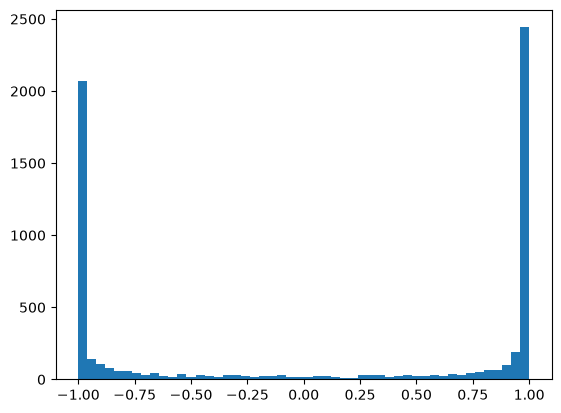

In [ ]:
plt.hist(h.view(-1).tolist(), 50) # visualize the distribution of the h value after activation

Obviously, most of the h after activation is clustered around -1 and 1, and the reason behind can be found by inspecting the distribution of hpreact (before activation): **The distribution is too broad**

(array([  2.,   2.,   1.,   4.,   2.,   4.,   6.,  15.,   5.,  25.,  32.,
         49.,  56.,  59.,  92., 119., 134., 197., 195., 221., 257., 275.,
        297., 341., 353., 375., 369., 349., 358., 362., 271., 312., 229.,
        206., 190., 167.,  87., 111.,  72.,  55.,  41.,  22.,  23.,  18.,
         17.,   8.,   5.,   7.,   2.,   1.]),
 array([-19.05793762, -18.31571915, -17.57350067, -16.8312822 ,
        -16.08906372, -15.34684525, -14.60462677, -13.86240829,
        -13.12018982, -12.37797134, -11.63575287, -10.89353439,
        -10.15131592,  -9.40909744,  -8.66687897,  -7.92466049,
         -7.18244202,  -6.44022354,  -5.69800507,  -4.95578659,
         -4.21356812,  -3.47134964,  -2.72913116,  -1.98691269,
         -1.24469421,  -0.50247574,   0.23974274,   0.98196121,
          1.72417969,   2.46639816,   3.20861664,   3.95083511,
          4.69305359,   5.43527206,   6.17749054,   6.91970901,
          7.66192749,   8.40414597,   9.14636444,   9.88858292,
         10.630801

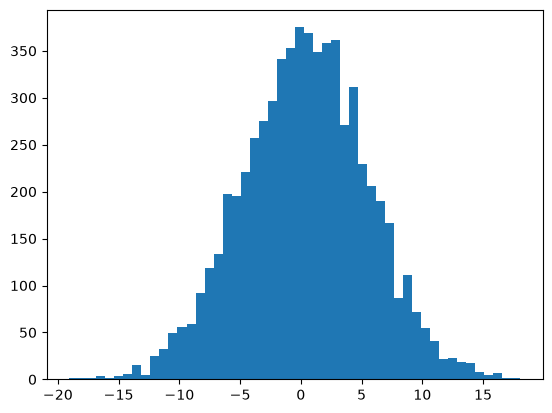

In [ ]:
plt.hist(hpreact.view(-1).tolist(), 50)

The reason why this is problem is that when the hpreact is too far away from zero, the result of its grad when doing back propogation would be virtually zero (look at the derivative formula for tanh). As a result, the model will think that changing the weights affect the hpreact too far from 0 will have no effect on the h (after activation). 

here we can try to see how many of the h after activation is so extreme that its abs is beyond 0.99. 

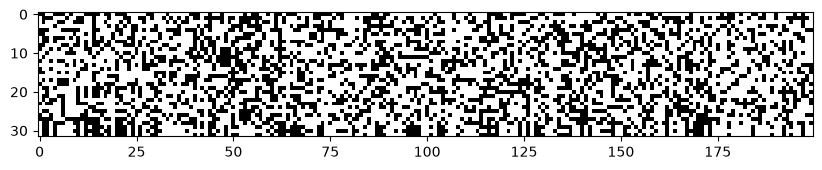

In [ ]:
plt.figure(figsize={20, 10})
plt.imshow(h.abs() > 0.99, cmap = 'gray', interpolation = 'nearest')
# h.abs() is a boolean tensor, and the grid is going to be white if it is true and black if false


Since the majority of the graph is white, we know that a lot of h value is very inactive, and on a flat tail. and for almost all of the the backward gradient will get destroyed. 

If we ever have a column that is completely white, then we will have a "dead neuron" since it is very hard to change the value of this column, after all, the h is never in the activated region of the tanh. **It will never learn**

Luckily, that is not the case here. 

And that is also a problem of a learning rate too big, since the step can just push h over the inactivated region and kill it, and chance is that it will just remain dead there in the following iteration of fitting, just like a person suffering from permanent brain damage. 

There are some activation functions that can fix the problem, like leaky ReLU, and ELU, since their solve are never really zero.

![activation functions](act_func.webp)

As seen, the problem is actually just that the hpreact are too far from 0, so we just need to make it so that the values are closer to zero, which can be done by modify W1 and b1. 

For W1, we can just multiply it by 0.2, and for b1 we multiply it by 0.01: the reason why we do not just put b1 altogether to 0 is that we want to give it a little variation and diversity instead of just making it to 0. 

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 0.2
b1 = torch.randn(n_hidden,                          generator = g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [ ]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3135


And that seems to be able to fix the problem

(array([143., 172., 172., 161., 142., 151., 133., 116., 116., 143.,  95.,
        104., 126., 111., 119.,  91.,  86.,  90., 115., 100., 112., 122.,
        111.,  77., 103., 119., 100., 106.,  91.,  90., 117., 114., 116.,
        115., 107., 131., 111., 109., 114., 118., 142., 127., 162., 169.,
        152., 197., 184., 192., 208., 198.]),
 array([-9.98924255e-01, -9.58988956e-01, -9.19053657e-01, -8.79118358e-01,
        -8.39183059e-01, -7.99247760e-01, -7.59312460e-01, -7.19377161e-01,
        -6.79441862e-01, -6.39506563e-01, -5.99571264e-01, -5.59635965e-01,
        -5.19700665e-01, -4.79765366e-01, -4.39830067e-01, -3.99894768e-01,
        -3.59959469e-01, -3.20024170e-01, -2.80088871e-01, -2.40153571e-01,
        -2.00218272e-01, -1.60282973e-01, -1.20347674e-01, -8.04123747e-02,
        -4.04770756e-02, -5.41776419e-04,  3.93935227e-02,  7.93288219e-02,
         1.19264121e-01,  1.59199420e-01,  1.99134719e-01,  2.39070019e-01,
         2.79005318e-01,  3.18940617e-01,  3.58875

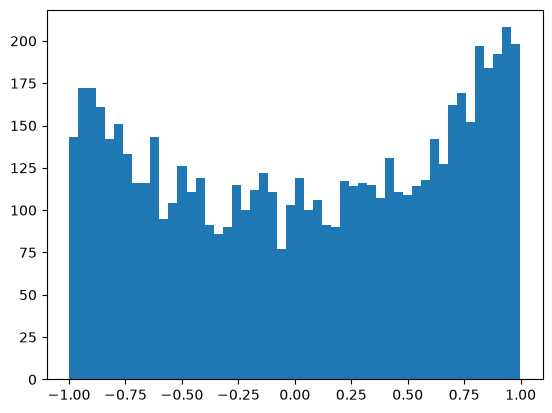

In [ ]:
plt.hist(h.view(-1).tolist(), 50) # visualize the distribution of the h value after activation

(array([  1.,   2.,   0.,   1.,   5.,   3.,  11.,   6.,  13.,  10.,  25.,
         40.,  40.,  77.,  63., 101., 127., 171., 184., 220., 227., 267.,
        312., 301., 356., 367., 376., 360., 370., 331., 298., 278., 292.,
        242., 191., 167., 137., 104.,  85.,  77.,  41.,  30.,  28.,  20.,
         11.,   7.,  11.,   5.,   2.,   7.]),
 array([-3.76367116, -3.6200974 , -3.47652364, -3.33294988, -3.18937612,
        -3.04580235, -2.90222859, -2.75865483, -2.61508107, -2.47150731,
        -2.32793355, -2.18435979, -2.04078603, -1.89721227, -1.75363851,
        -1.61006474, -1.46649098, -1.32291722, -1.17934346, -1.0357697 ,
        -0.89219594, -0.74862218, -0.60504842, -0.46147466, -0.3179009 ,
        -0.17432714, -0.03075337,  0.11282039,  0.25639415,  0.39996791,
         0.54354167,  0.68711543,  0.83068919,  0.97426295,  1.11783671,
         1.26141047,  1.40498424,  1.548558  ,  1.69213176,  1.83570552,
         1.97927928,  2.12285304,  2.2664268 ,  2.41000056,  2.55357432,
 

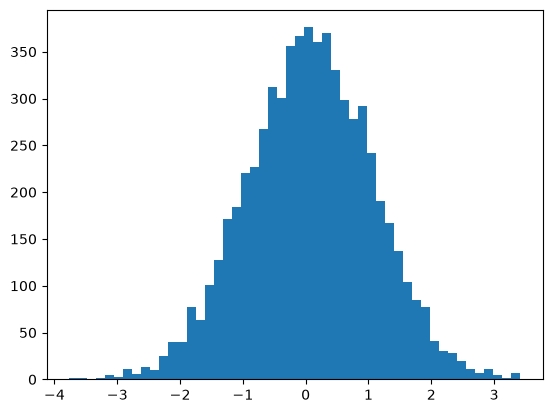

In [ ]:
plt.hist(hpreact.view(-1).tolist(), 50) # visualize the distribution of the h value after activation

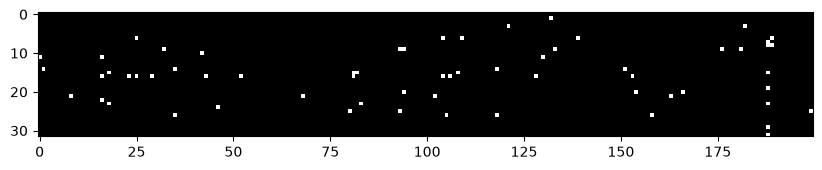

In [ ]:
plt.figure(figsize={20, 10})
plt.imshow(h.abs() > 0.99, cmap = 'gray', interpolation = 'nearest')
# h.abs() is a boolean tensor, and the grid is going to be white if it is true and black if false


yay

In [ ]:
# full run again
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.2465
  10000/ 200000: 2.1648
  20000/ 200000: 2.3061
  30000/ 200000: 2.4541
  40000/ 200000: 1.9787
  50000/ 200000: 2.2930
  60000/ 200000: 2.4232
  70000/ 200000: 2.0680
  80000/ 200000: 2.3095
  90000/ 200000: 2.1207
 100000/ 200000: 1.8269
 110000/ 200000: 2.2052
 120000/ 200000: 1.9796
 130000/ 200000: 2.3947
 140000/ 200000: 2.1000
 150000/ 200000: 2.1949
 160000/ 200000: 1.8619
 170000/ 200000: 1.7810
 180000/ 200000: 1.9673
 190000/ 200000: 1.8295
 200000/ 200000: 2.3023


In [ ]:
split_loss('train')
split_loss('val')

train 2.035708427429199
val 2.1029491424560547


# third issue: the way to get the magical number (0,2, 0.01, 0.01, 0.1) that gives a good initial parameters that even some large neural network allows. 

tensor(0.0140) tensor(1.0035)
tensor(0.0018) tensor(3.1536)


(array([6.23469296e-06, 0.00000000e+00, 6.23469296e-06, 0.00000000e+00,
        6.23469296e-06, 1.87040789e-05, 2.49387718e-05, 7.48163155e-05,
        9.97550874e-05, 3.05499955e-04, 3.36673420e-04, 5.73591752e-04,
        1.09730596e-03, 1.92652012e-03, 3.26697911e-03, 5.36807064e-03,
        9.29592721e-03, 1.40904061e-02, 2.27566293e-02, 3.48955765e-02,
        5.09187374e-02, 6.99096122e-02, 9.21175885e-02, 1.14256983e-01,
        1.28964624e-01, 1.36757990e-01, 1.30354960e-01, 1.15516391e-01,
        9.29343333e-02, 7.23411424e-02, 5.19911046e-02, 3.53818826e-02,
        2.36170169e-02, 1.47450489e-02, 9.42062106e-03, 5.54264204e-03,
        3.47272398e-03, 1.99510175e-03, 1.12224473e-03, 5.98530524e-04,
        3.92785657e-04, 1.68336710e-04, 1.18459166e-04, 5.61122367e-05,
        5.61122367e-05, 1.87040789e-05, 6.23469296e-06, 6.23469296e-06,
        0.00000000e+00, 6.23469296e-06]),
 array([-20.47496223, -19.67299812, -18.87103401, -18.0690699 ,
        -17.26710579, -16.4651

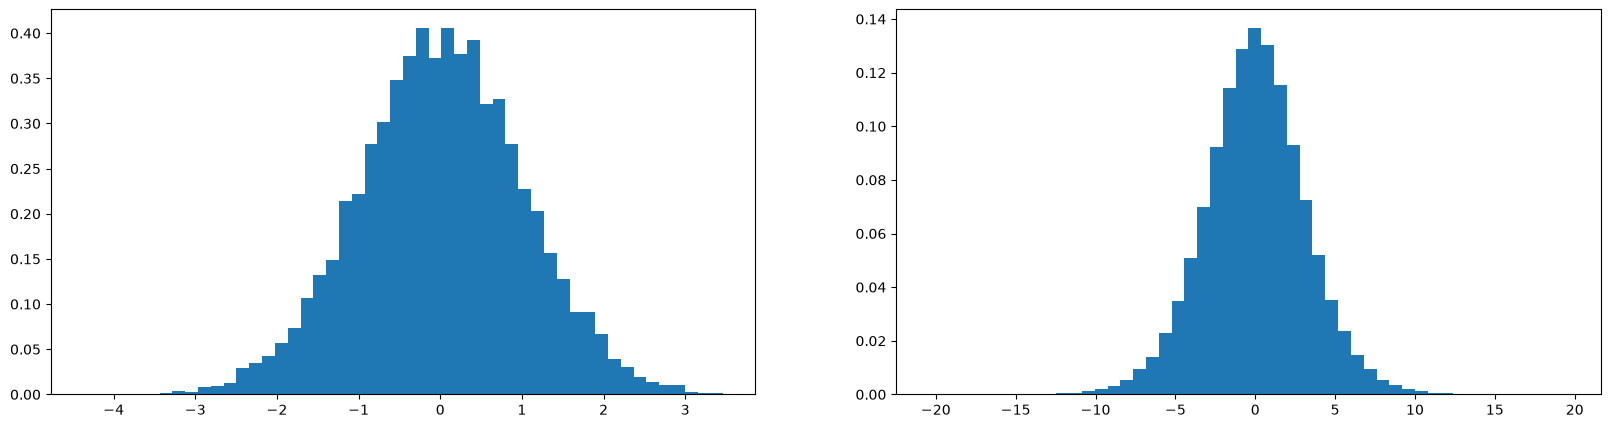

In [12]:
X = torch.randn(1000, 10)
W = torch.randn(10, 200)
y = X @ W
print(X.mean(), X.std())
print(y.mean(), y.std())
plt.figure(figsize = (20, 5))
plt.subplot(121)
plt.hist(X.view(-1).tolist(), 50, density = True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density = True)

obviously, the std increases, so the problem becomes how to preserve the width. of the distribution, since we want the activations to take on reasonable values. And the math behind shows that we scale the W down by the square root of fan-in (in this case, 10), like the cell below:

tensor(0.0130) tensor(0.9986)
tensor(-0.0006) tensor(1.0072)


(array([2.15762061e-05, 0.00000000e+00, 0.00000000e+00, 4.31524122e-05,
        4.31524122e-05, 8.63048245e-05, 1.51033443e-04, 3.45219298e-04,
        6.90438596e-04, 1.01408169e-03, 1.66136787e-03, 2.61072094e-03,
        5.48035636e-03, 7.05541940e-03, 1.26436568e-02, 2.01090241e-02,
        3.10481606e-02, 4.81365159e-02, 7.10720230e-02, 1.05809715e-01,
        1.46890811e-01, 1.97508591e-01, 2.60338503e-01, 3.26340118e-01,
        3.81078953e-01, 4.21491187e-01, 4.28222963e-01, 4.09796883e-01,
        3.59912694e-01, 2.93112760e-01, 2.28707785e-01, 1.72631225e-01,
        1.25098843e-01, 8.69305345e-02, 5.98739720e-02, 4.02827768e-02,
        2.54383470e-02, 1.67215597e-02, 1.09175603e-02, 6.96911458e-03,
        3.75425987e-03, 2.17919682e-03, 1.25141996e-03, 8.41472039e-04,
        3.45219298e-04, 2.37338267e-04, 1.51033443e-04, 1.07881031e-04,
        4.31524122e-05, 4.31524122e-05]),
 array([-6.08871508, -5.85697832, -5.62524157, -5.39350481, -5.16176805,
        -4.9300313 , 

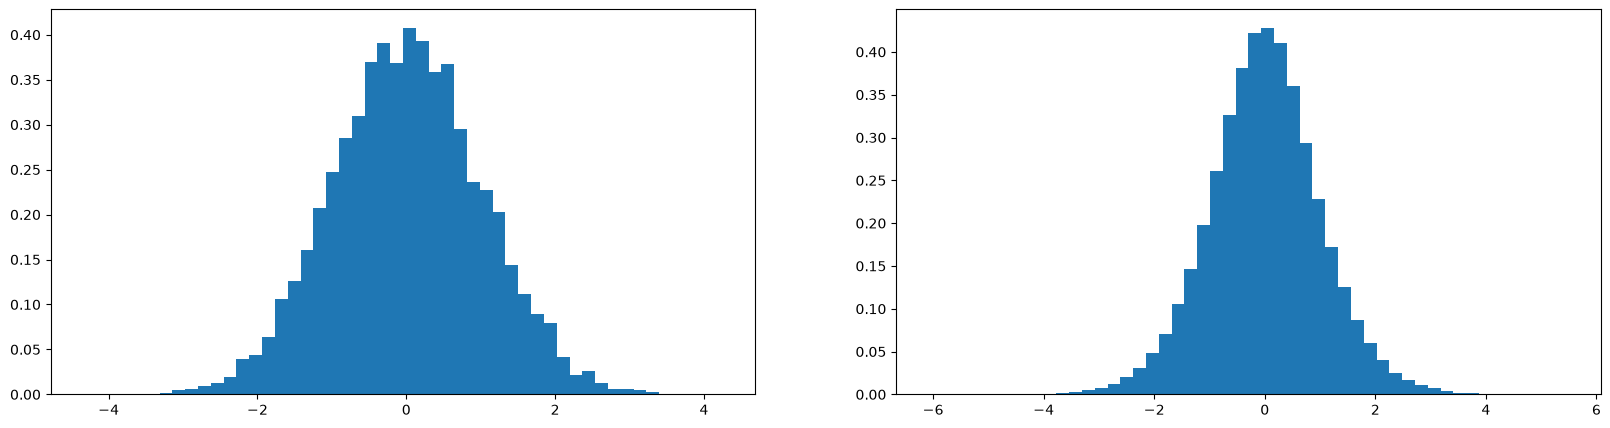

In [ ]:
X = torch.randn(1000, 10)
W = torch.randn(10, 200) / 10 ** 0.5
y = X @ W
print(X.mean(), X.std())
print(y.mean(), y.std())
plt.figure(figsize = (20, 5))
plt.subplot(121)
plt.hist(X.view(-1).tolist(), 50, density = True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density = True)

In the situation, above the scaling is very easy to figure out since it is just straghtforward matrix multiplication. However, things can get complicated when activation functions come into play. Most of the activation functions squash the distribution (mapping the input into a smaller range, like tanh: R -> (-1, 1)), and because of that, the standard deviation decreases, and therefore, in addition to dividing the square root of fan_in we need to add another factor that pushes against this effect of "squash", which we call **gain**. And as expected, different activation functions have different gain. 

| Activation Function | Recommended Gain | Common Use |
|:---|:---:|:---|
| Linear / Identity | $1$ | Linear layers |
| Sigmoid | $1$ | Output layers |
| Tanh | $\frac{5}{3}$ | Hidden layers |
| ReLU | $\sqrt{2}$ | Deep neural networks, CNNs |
| Leaky ReLU | $\sqrt{\frac{2}{1+a^2}}$ | Preventing dead neurons |
| SELU | $\frac{3}{4}$ | Self-normalizing neural networks |

$$
\text{std} = \frac{\text{gain}}{\sqrt{\text{fan\_in}}}
$$

Where:

- $\text{gain}$ is determined by the activation function.
- $\text{fan\_in}$ is the number of input connections to a neuron.

And obviously in our case, we need to scale the standard initialized weights by ```(5/3) / sqrt(block_size * embd_size)```

In [82]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 / (n_embd * block_size) ** 0.5 # * 0.2
b1 = torch.randn(n_hidden,                          generator = g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

11897


In [83]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3179
  10000/ 200000: 2.4019
  20000/ 200000: 1.7376
  30000/ 200000: 2.2110
  40000/ 200000: 2.2503
  50000/ 200000: 2.3602
  60000/ 200000: 1.6995
  70000/ 200000: 1.9172
  80000/ 200000: 2.2547
  90000/ 200000: 2.1491
 100000/ 200000: 2.0761
 110000/ 200000: 1.9925
 120000/ 200000: 2.0562
 130000/ 200000: 2.1142
 140000/ 200000: 1.8885
 150000/ 200000: 2.5708
 160000/ 200000: 2.0053
 170000/ 200000: 1.6470
 180000/ 200000: 1.6652
 190000/ 200000: 2.1971
 200000/ 200000: 2.3840


tensor(0.7641, grad_fn=<StdBackward0>)

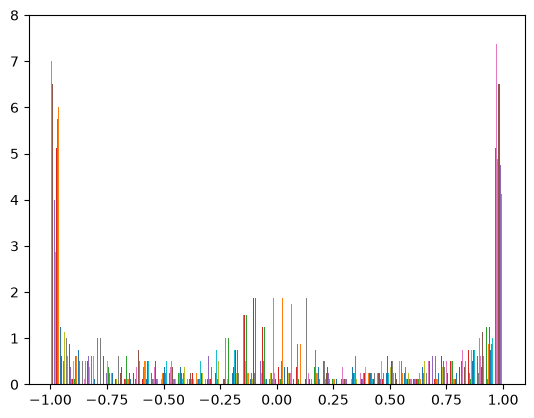

In [84]:
plt.hist(h.tolist(), 50, density = True)
h.std()

In [85]:
split_loss('train')
split_loss('val')

train 2.0376641750335693
val 2.1069893836975098


# Innovation 1: batch normalization

In the issue three, what we did was to make sure that the hpreact is guassian perfectly, with mean 0 sd 1. And instead of tuning the scaling of the weights, we can directly perform some operation on hpreact to make it perfectly Guassian, which we can **Batch Normalization**. The code is below

```hpreact = (hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True)```

However, if we directly put that into the code directly under the line calculating hpreact, the result wont be so good. (train 2.770920991897583
val 2.79845929145813) That is because during the training iterations, we are always forcing it to be Guassian, while the weights need freedom to change so that they can move around and take on the value that it needs to minimize the loss function. 

The solution is that after the batch normalization, we scale the result by the gain, and shift the distribution by some bias so that the model is able to move hpreact around to a comfortable place. And to do that, we obviously need two additional parameters: 

In [1]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 / (n_embd * block_size) ** 0.5 # * 0.2
b1 = torch.randn(n_hidden,                          generator = g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0

bngain = torch.ones(1, n_hidden) # no scaling upon initialization
bnbias = torch.zeros(1, n_hidden) # no bias upon initialization

parameters = [C, W1, b1, W2, b2, bngain, bnbias] # remember to add the additional two
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

NameError: name 'torch' is not defined

In [ ]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    hpreact = bngain * (hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True) + bnbias
    # batch normalization
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

      1/ 200000: 3.3147
  10000/ 200000: 2.3447
  20000/ 200000: 1.6538
  30000/ 200000: 2.1507
  40000/ 200000: 2.3664
  50000/ 200000: 2.4183
  60000/ 200000: 1.6551
  70000/ 200000: 2.0256
  80000/ 200000: 2.2026
  90000/ 200000: 2.2033
 100000/ 200000: 2.1167
 110000/ 200000: 2.0459
 120000/ 200000: 1.9769
 130000/ 200000: 2.1556
 140000/ 200000: 1.8915
 150000/ 200000: 2.4565
 160000/ 200000: 2.1542
 170000/ 200000: 1.6805
 180000/ 200000: 1.7265
 190000/ 200000: 2.0129
 200000/ 200000: 2.4315


In [ ]:
@torch.no_grad() # this decorator disables gradient tracking

def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1
    hpreact = bngain * (hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True) + bnbias
    h = torch.tanh(hpreact) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')
    

train 2.0668270587921143
val 2.104844808578491


In [ ]:
@torch.no_grad() # this decorator disables gradient tracking

def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1
    hpreact = bngain * (hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True) + bnbias
    h = torch.tanh(hpreact) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')
    

train 2.0668270587921143
val 2.104844808578491


The stablity brought by the batch normalization comes at cost: when going through an iteration, the update of the parameters depend on the exact sameples drawn by the random chance. Tt inevitably causes a noise and some jittering in the parameter datas. However, that is actually desirable in the training since we do not want overfitting. 

However, there is another trouble introduced by batch normalization. When deploying the model, there is no "batch" for us to calculate the batch mean and batch standard deviation. Therefore, we just calculate the overall mean and standard deviation across the whole training set to get a constant value, which is to be used in the process of deploying. 

In [ ]:
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    bnmean = hpreact.mean(0, keepdims = True) 
    bnstd = hpreact.std(0, keepdims = True)
print(bnmean)
print(bnstd)


tensor([[-2.3355,  0.6776, -0.9133,  1.0163,  1.0865,  1.0938,  1.7437, -2.1208,
          0.5730,  1.4455, -1.6343, -2.7372, -0.4752, -0.1412, -0.0745, -1.1722,
          0.6851, -2.6219, -0.1065,  1.6326, -0.7706, -0.3062,  0.0479,  0.6115,
          1.1173,  0.2427,  2.0500,  0.5831,  0.8527,  1.7680, -0.3625, -0.8356,
         -0.0854, -0.5177, -0.3806, -1.0699, -0.0786,  0.3487, -0.5808,  0.9875,
         -0.4427, -1.3082, -0.2871, -0.2332,  0.6850,  0.6850,  2.0857, -0.7608,
          2.3866,  1.8734,  0.8259,  0.2803,  1.8897,  0.4709,  0.6739, -1.8940,
         -0.0401,  0.4338,  1.3760, -0.8910, -0.4524,  1.1754,  0.5613,  0.6051,
          1.5859,  1.2260, -1.0111,  2.1495, -0.6393,  0.0938, -0.2864, -0.4856,
          0.9632, -1.0461, -2.9990,  0.6391,  1.4327, -0.1590,  0.0941,  0.5253,
          0.2508,  1.2521,  2.0389,  0.6608,  0.0691, -0.0813, -1.6724,  0.2933,
          2.2423, -0.0211, -0.6666,  1.4253, -0.8411, -1.2248, -1.0128,  0.2230,
          0.2112, -0.3226,  

In [ ]:
@torch.no_grad() # this decorator disables gradient tracking

def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1
    # hpreact = bngain * (hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True) + bnbias
    # we use the mean and sd created above to calculate the same thing
    hpreact = bngain * (hpreact - bnmean)/bnstd + bnbias
    h = torch.tanh(hpreact) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0668270587921143
val 2.104926824569702


Another idea is that we do not need to calculate the bnmean nad bnstd of the whole training data, and instead, we can create a running std and mean and change along the way of training since that will be closer to the result and process along the way of training. And the implementation is below. 

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 / (n_embd * block_size) ** 0.5 # * 0.2
b1 = torch.randn(n_hidden,                          generator = g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0

bngain = torch.ones(1, n_hidden) # no scaling upon initialization
bnbias = torch.zeros(1, n_hidden) # no bias upon initialization
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias] # remember to add the additional two
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

12297


In [ ]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    bnmeani = hpreact.mean(0, keepdims = True)
    bnstdi = hpreact.std(0, keepdims = True)
    hpreact = bngain * (hpreact - bnmeani)/bnstdi + bnbias

    # the update of bnmean_running and bnstd_running with tracking grad
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    
    # batch normalization
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

print(bnmean_running)
print(bnstd_running)

      1/ 200000: 3.3147
  10000/ 200000: 2.3447
  20000/ 200000: 1.6538
  30000/ 200000: 2.1507
  40000/ 200000: 2.3664
  50000/ 200000: 2.4183
  60000/ 200000: 1.6551
  70000/ 200000: 2.0256
  80000/ 200000: 2.2026
  90000/ 200000: 2.2033
 100000/ 200000: 2.1167
 110000/ 200000: 2.0459
 120000/ 200000: 1.9769
 130000/ 200000: 2.1556
 140000/ 200000: 1.8915
 150000/ 200000: 2.4565
 160000/ 200000: 2.1542
 170000/ 200000: 1.6805
 180000/ 200000: 1.7265
 190000/ 200000: 2.0129
 200000/ 200000: 2.4315
tensor([[-2.3539,  0.6872, -0.9000,  1.0159,  1.0894,  1.0862,  1.7389, -2.1357,
          0.5608,  1.4246, -1.6445, -2.7426, -0.4861, -0.1510, -0.0687, -1.1550,
          0.6891, -2.6399, -0.1283,  1.6240, -0.7732, -0.2864,  0.0467,  0.6119,
          1.1172,  0.2433,  2.0542,  0.5778,  0.8515,  1.7729, -0.3741, -0.8385,
         -0.0831, -0.5198, -0.3817, -1.0699, -0.0780,  0.3370, -0.5768,  0.9935,
         -0.4507, -1.3313, -0.2895, -0.2299,  0.6877,  0.6936,  2.0835, -0.7759,
          

As you can check, the explicitly defined and deterministic bnmean and bnstd are very similar to the running bnmean and bnstd, and therefore, this method to track bnmean and bnstd is feasible and reliable. 

Two additional notes: 

First, if you go over the paper about batch normalization, you will see that when they do the batch normalization and calculate the result after normalization, they add a small positive number epsilon in the denominator. that epsilon is introduced to prevent the case in which the the standard deviation is zero, which is virtually impossible in our situation, so it is unnecessary to introduce the epsilon here. 

Secondly, we are being wasteful in the aspect of memory: b1, it is completely useless and after adding the bias to hpreact, we subtract it with bnmeani. Therefore, one should not initialize the bias if there is going to be batch normalization. (bnbias will take care of that). The updated version is below with comments. 

In [ ]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 / (n_embd * block_size) ** 0.5 # * 0.2
# b1 = torch.randn(n_hidden,                          generator = g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.randn(vocab_size,                        generator = g) * 0

bngain = torch.ones(1, n_hidden) # no scaling upon initialization
bnbias = torch.zeros(1, n_hidden) # no bias upon initialization
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias] # remember to add the additional two
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

In [ ]:
# hyperparameters
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the embedding vectors
    # Linear layer
    hpreact = embcat @ W1 # + b1 # hidden layer pre-activation
    # BatchNorm layer
    # -------------------------------------------------
    bnmeani = hpreact.mean(0, keepdims = True)
    bnstdi = hpreact.std(0, keepdims = True)
    hpreact = bngain * (hpreact - bnmeani)/bnstdi + bnbias
    # the update of bnmean_running and bnstd_running with tracking grad
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # -------------------------------------------------
    # Non-linearity
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats
    if i == 0:
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    if (i+1) % 10000 == 0: # print loss function value once in a while
        print(f'{i+1:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break # we put a break here just to check the loss upon initialization

print(bnmean_running)
print(bnstd_running)

Batch normalization is often used after a layer of neurons with multiplication or convolutional neural network, which will be covered later. the overall structure is linear (no bias), normalization, nonlinear(tanh), which will also be the motif for larger model

And guess what, pytorch has done that for us. 

![linear](linear.png)

in_feature is just fanin, and out_feature is just fanout. 

And if normalization is to be used later, the bias should be set to False. 

A distinction is that the parameters of weight and bias upon initialization is a uniform distribution instead of a normal distribution, and the range of the uniform distribution is determined by the in_features. 

![normalization1](normalization1.png)

![normalization2](normalization2.png)

The asme we need to know the normalized shape

You also an epsilon which was eliminated in our case. its value is a negligible 10**-5, which we do not usually change. 

You also need the momentum, which is the speed at which the running mean and running std change. The default value is 0.1, but in our example the momentum is 0.01. We may need to change it sometimes. for a. small batch size, their changing may be significant, so we cannot use a momentum as large as 0.1. therefore, with a small batch size, we want a smaller momentum so that the running mean nad std are not thrashing around.

affine and bias are just bngain and bnbias, which are almost kept true always. 

tracking_running_stats will determine whether the loop will keep updating the runnign mean and std. 

Device: Cpu or Gpu. 

# Torchifying

In [81]:
# linear layer
class Linear:

    def __init__(self, fan_in, fan_out, bias = True):
        self.weight = torch.randn((fan_in, fan_out), generator = g) / fan_in ** 0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias == None else [self.bias])

In [134]:
# batch normalization
class Batchnorm1d:

    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters
        self.gamma = torch.ones(dim) # gamma, and beta used in torch API
        self.beta = torch.zeros(dim)
        # buffers (running mean and standard deviation)
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            xmean = x.mean(0, keepdims=True)
            xvar = x.std(0, keepdims=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x-xmean)/torch.sqrt(xvar**2 + self.eps)
        self.out = self.gamma * xhat + self.beta
        # updating the buffers
        if self.training:
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean 
            self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma ,self.beta]

In [83]:
class Tanh:

    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

In [102]:
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd),                   generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Tanh(),
    Linear(           n_hidden, vocab_size),
]

with torch.no_grad():
    # last layer: make less confident
    layers[-1].weight *= 0.1
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

46497


In [103]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
up = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG: would take out the retain_graph
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    with torch.no_grad():
        up.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    if i >= 1000:
        break 


      0/ 200000: 3.2962


Layer 1 (<class '__main__.Tanh'>): mean -0.04, std 0.76, saturated: 21.97%
Layer 3 (<class '__main__.Tanh'>): mean -0.01, std 0.72, saturated: 11.00%
Layer 5 (<class '__main__.Tanh'>): mean +0.01, std 0.73, saturated: 13.00%
Layer 7 (<class '__main__.Tanh'>): mean -0.05, std 0.73, saturated: 13.34%
Layer 9 (<class '__main__.Tanh'>): mean +0.00, std 0.72, saturated: 10.53%


Text(0.5, 1.0, 'activation distribution')

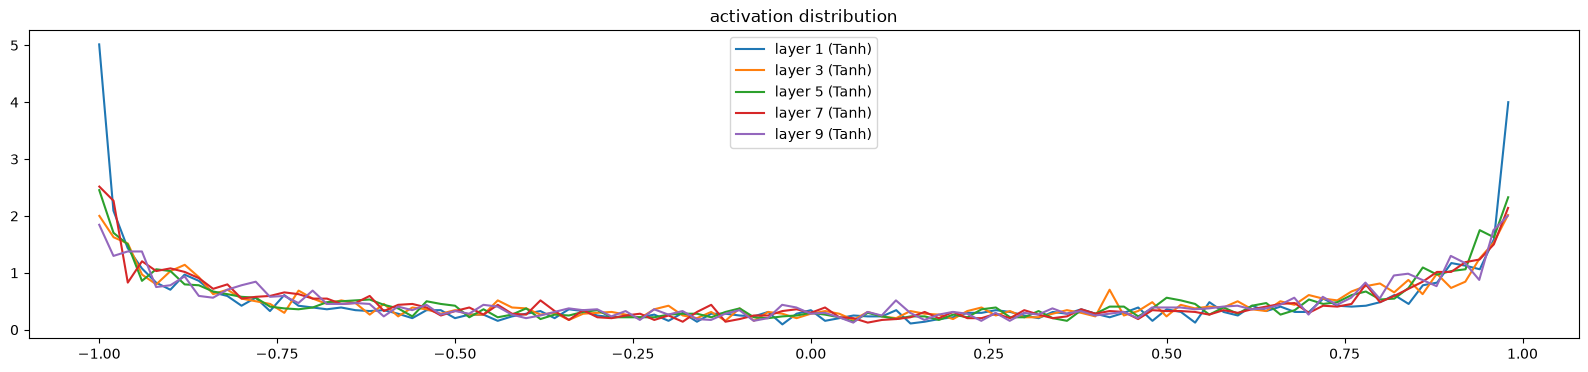

In [104]:
# visualize histogram (activation)
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, layer in enumerate(layers[:-1]): # not considering the last softmax layer. 
    if isinstance(layer, Tanh): # only taking tanh layer
        t = layer.out
        print('Layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__, t.mean(), t.std(), (t.abs() > 0.97).float().mean() * 100))
        # we do not want the saturated percentage to be too high. 
        hy, hx = torch.histogram(t, density = True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('activation distribution')

Layer 1 (<class '__main__.Tanh'>): mean +0.00, std 0.00
Layer 3 (<class '__main__.Tanh'>): mean +0.00, std 0.00
Layer 5 (<class '__main__.Tanh'>): mean -0.00, std 0.00
Layer 7 (<class '__main__.Tanh'>): mean +0.00, std 0.00
Layer 9 (<class '__main__.Tanh'>): mean +0.00, std 0.00


Text(0.5, 1.0, 'gradient distribution')

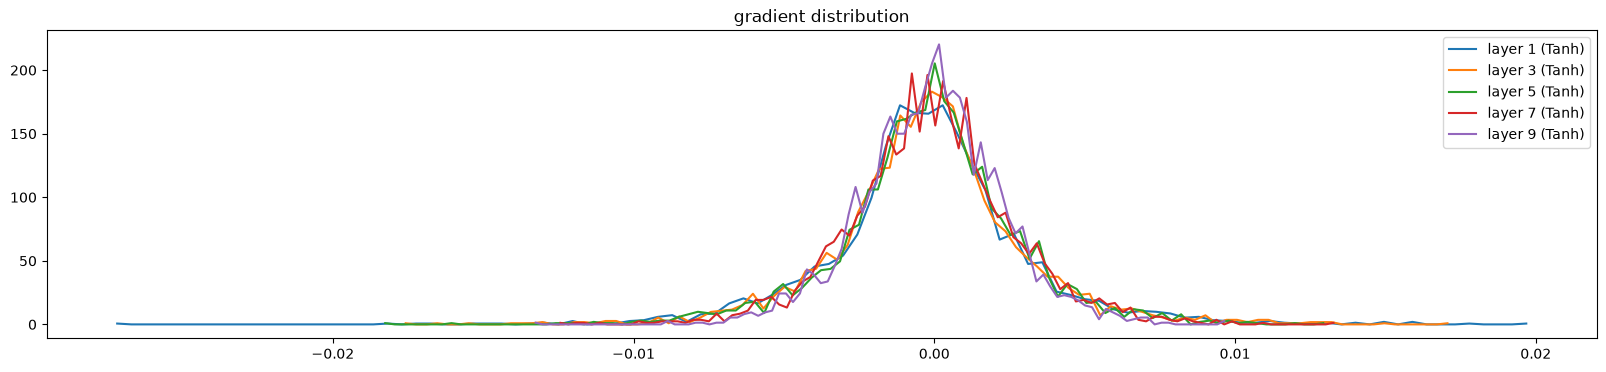

In [105]:
# visualize histogram (gradient )
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, layer in enumerate(layers[:-1]): # not considering the last softmax layer. 
    if isinstance(layer, Tanh): # only taking tanh layer
        t = layer.out.grad
        print('Layer %d (%10s): mean %+.2f, std %.2f' % (i, layer.__class__, t.mean(), t.std()))
        # we do not want the saturated percentage to be too high. 
        hy, hx = torch.histogram(t, density = True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

The gradient is generally reasonable, and the gradient across different tanh layers are similar, neither shrinking nor exploding

weight   (27, 10) | mean -0.000495 | std 1.099105e-02 | grad: data ratio 1.097200e-02
weight  (30, 100) | mean +0.000041 | std 1.009662e-02 | grad: data ratio 3.224283e-02
weight (100, 100) | mean +0.000020 | std 7.804845e-03 | grad: data ratio 4.645311e-02
weight (100, 100) | mean +0.000046 | std 7.009212e-03 | grad: data ratio 4.137613e-02
weight (100, 100) | mean -0.000069 | std 6.341558e-03 | grad: data ratio 3.760276e-02
weight (100, 100) | mean +0.000020 | std 6.231392e-03 | grad: data ratio 3.692914e-02
weight  (100, 27) | mean -0.000114 | std 1.217139e-02 | grad: data ratio 7.098269e-02


Text(0.5, 1.0, 'gradient distribution')

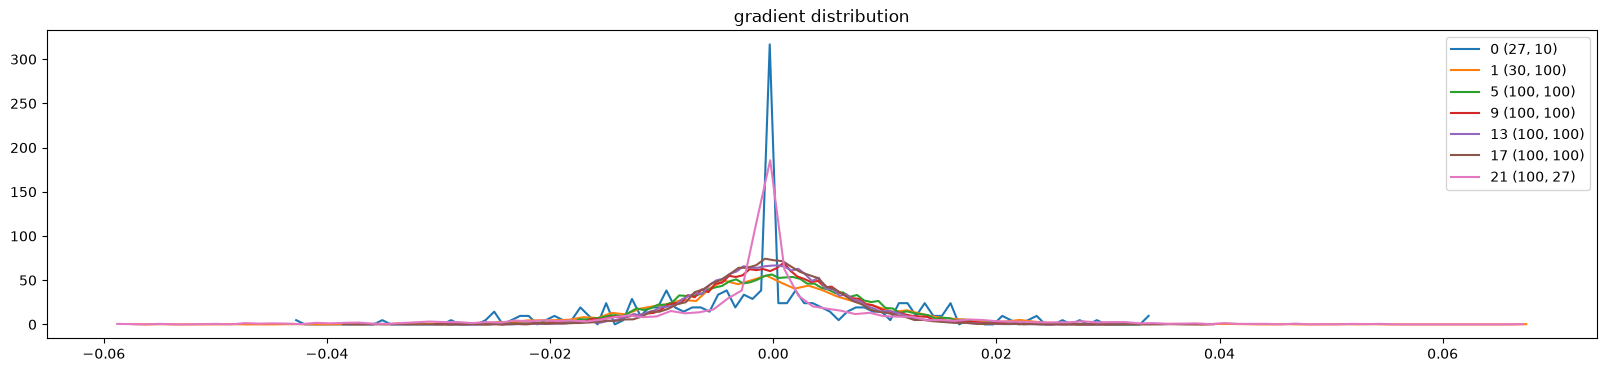

In [135]:
# visualize histogram (gradient )
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2: # (just checking whether it is linear layer or not)
        print("weight %10s | mean %+f | std %e | grad: data ratio %e" 
              % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std())
              )
        hy,hx = torch.histogram(t, density = True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"{i} {tuple(p.shape)}")
plt.legend(legends)
plt.title('gradient distribution')

There is some trouble with the last layer since its grad-data ratio is going too high, but actually this issue will be somehow reduced when the iteration times grow much higher than 1. 

However, this is still a problem that is to be solved by better optimizer like adam instead of a simple scholastic gradient descent. 

Text(0.5, 1.0, 'gradient distribution')

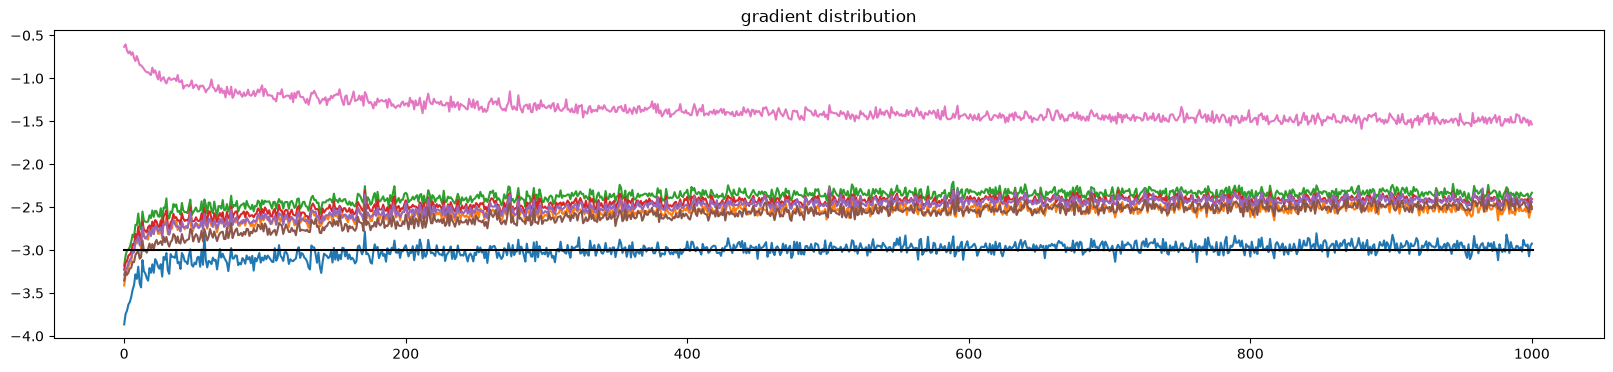

In [109]:
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2: # (just checking whether it is linear layer or not)
        plt.plot([up[j][i] for j in range(len(up))])
        legends.append('param %d' % i)
plt.plot([0, len(up)], [-3, -3], 'k') # these ratios should be about 1e-3 as indicaated on the plot
plt.title('gradient distribution')

The high head in the last layer is due to the addition of low confidence upon initialzation

Let us see what is the effect of batchnorm

In [136]:
n_embd = 10 # the dimensionality of character embedding vectors
n_hidden= 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd),                   generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, n_hidden), Batchnorm1d(n_hidden), Tanh(),
    Linear(           n_hidden, vocab_size), Batchnorm1d(vocab_size), # yeah you can also apply it in the end
]

with torch.no_grad():
    # last layer: make less confident
    layers[-1].gamma *= 0.1 # since the last layer changes its type
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

47551


In [137]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
up = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG: would take out the retain_graph
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    with torch.no_grad():
        up.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    if i >= 1000:
        break 


      0/ 200000: 3.2870


Layer 2 (<class '__main__.Tanh'>): mean -0.00, std 0.63, saturated: 2.62%
Layer 5 (<class '__main__.Tanh'>): mean +0.00, std 0.64, saturated: 2.47%
Layer 8 (<class '__main__.Tanh'>): mean -0.00, std 0.64, saturated: 2.16%
Layer 11 (<class '__main__.Tanh'>): mean +0.00, std 0.65, saturated: 1.81%
Layer 14 (<class '__main__.Tanh'>): mean -0.00, std 0.65, saturated: 1.78%


Text(0.5, 1.0, 'activation distribution')

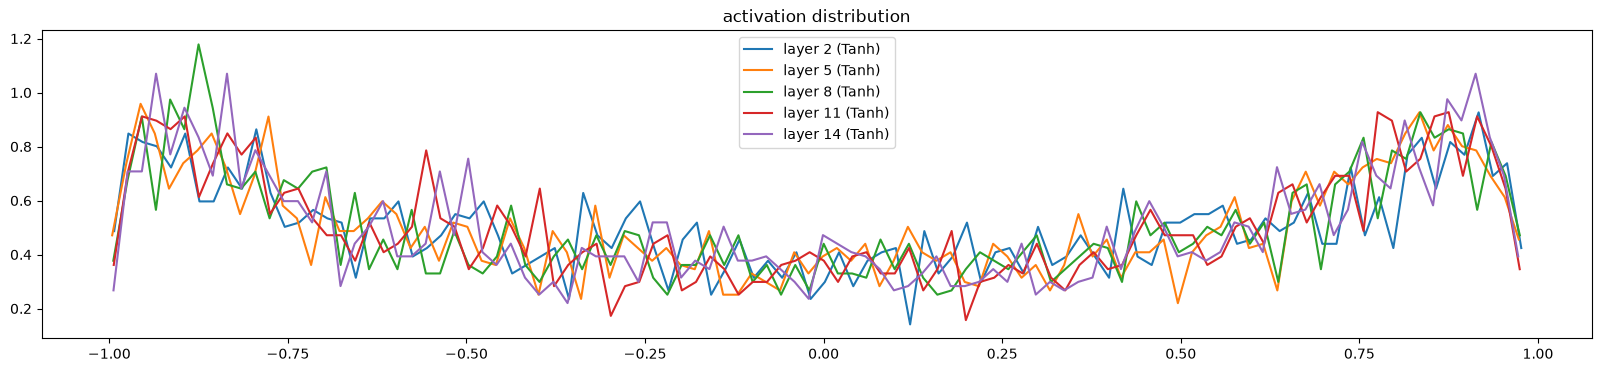

In [138]:
# visualize histogram (activation)
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, layer in enumerate(layers[:-1]): # not considering the last softmax layer. 
    if isinstance(layer, Tanh): # only taking tanh layer
        t = layer.out
        print('Layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__, t.mean(), t.std(), (t.abs() > 0.97).float().mean() * 100))
        # we do not want the saturated percentage to be too high. 
        hy, hx = torch.histogram(t, density = True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('activation distribution')

Since there is a normalization is added, so everything should look good

Layer 2 (<class '__main__.Tanh'>): mean +0.00, std 0.00
Layer 5 (<class '__main__.Tanh'>): mean -0.00, std 0.00
Layer 8 (<class '__main__.Tanh'>): mean +0.00, std 0.00
Layer 11 (<class '__main__.Tanh'>): mean -0.00, std 0.00
Layer 14 (<class '__main__.Tanh'>): mean +0.00, std 0.00


Text(0.5, 1.0, 'gradient distribution')

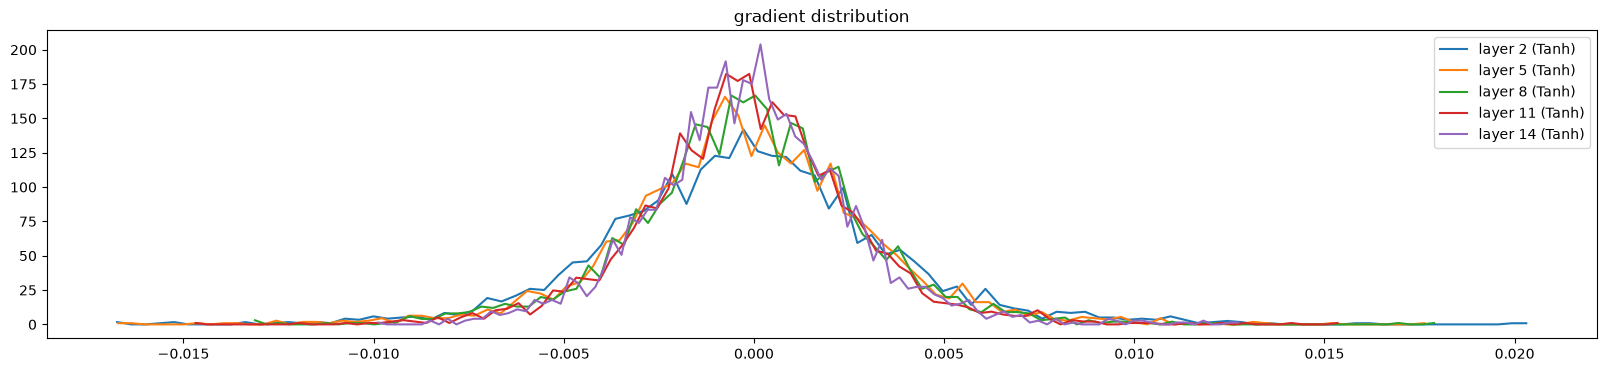

In [139]:
# visualize histogram (gradient )
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, layer in enumerate(layers[:-1]): # not considering the last softmax layer. 
    if isinstance(layer, Tanh): # only taking tanh layer
        t = layer.out.grad
        print('Layer %d (%10s): mean %+.2f, std %.2f' % (i, layer.__class__, t.mean(), t.std()))
        # we do not want the saturated percentage to be too high. 
        hy, hx = torch.histogram(t, density = True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title('gradient distribution')

weight   (27, 10) | mean +0.000000 | std 1.019882e-02 | grad: data ratio 1.018843e-02
weight  (30, 100) | mean +0.000092 | std 8.238417e-03 | grad: data ratio 2.635835e-02
weight (100, 100) | mean +0.000031 | std 7.318098e-03 | grad: data ratio 4.377136e-02
weight (100, 100) | mean -0.000019 | std 6.662020e-03 | grad: data ratio 3.949894e-02
weight (100, 100) | mean -0.000019 | std 5.821512e-03 | grad: data ratio 3.468158e-02
weight (100, 100) | mean +0.000053 | std 5.445290e-03 | grad: data ratio 3.243364e-02
weight  (100, 27) | mean -0.000165 | std 1.046843e-02 | grad: data ratio 6.281254e-02


Text(0.5, 1.0, 'gradient distribution')

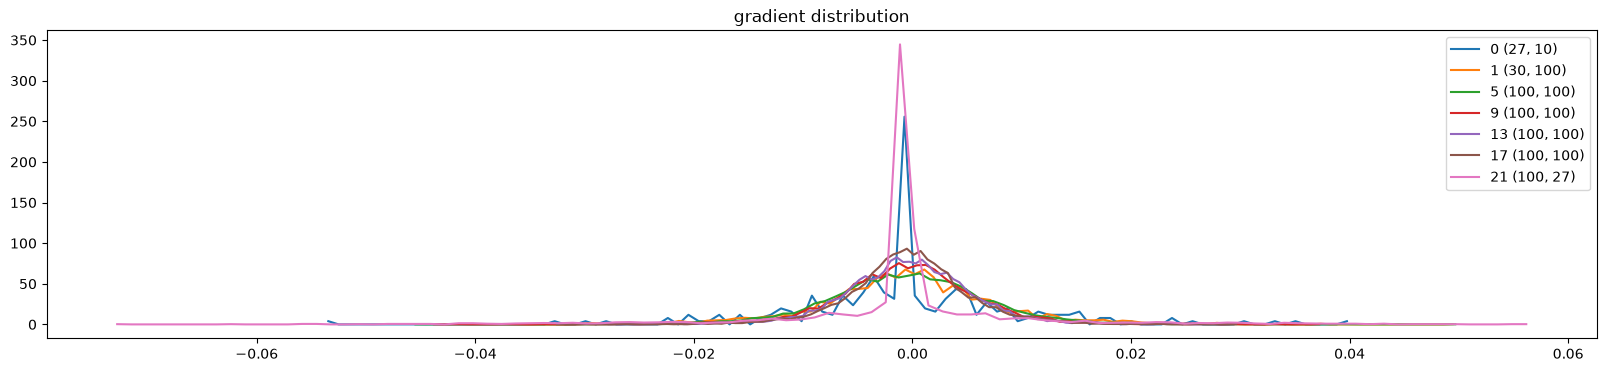

In [140]:
# visualize histogram (gradient )
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2: # (just checking whether it is linear layer or not)
        print("weight %10s | mean %+f | std %e | grad: data ratio %e" 
              % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std())
              )
        hy,hx = torch.histogram(t, density = True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"{i} {tuple(p.shape)}")
plt.legend(legends)
plt.title('gradient distribution')

Text(0.5, 1.0, 'gradient distribution')

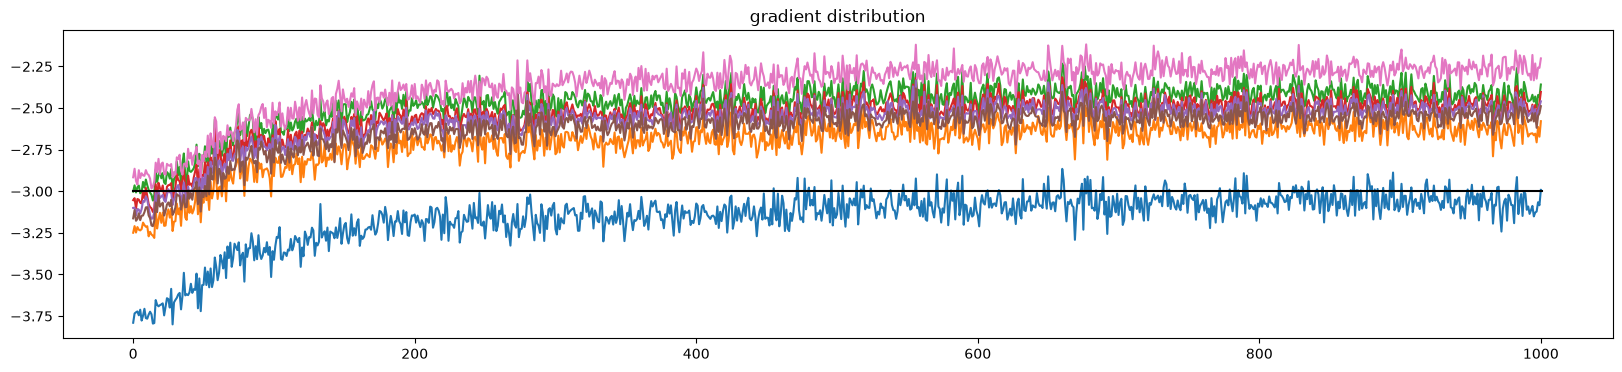

In [141]:
plt.figure(figsize = (20, 4)) # width and height of the hist
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2: # (just checking whether it is linear layer or not)
        plt.plot([up[j][i] for j in range(len(up))])
        legends.append('param %d' % i)
plt.plot([0, len(up)], [-3, -3], 'k') # these ratios should be about 1e-3 as indicaated on the plot
plt.title('gradient distribution')

To be honest, due to the presence of those normalization layers, we can directlt abandon the gain and the divsion by sqrt(fan_in) since the scaling will be taken care of by the batch norm layer. However, it is worth noting that although the effect on the first three graph is not very significant, it impacts the fourth graph somehow, that is bcause the value from back prpogation will change, and therefore, we may want to calibrate the learning rate for the curves in the fourth to mett 1e-3. 

# loss log

loss log:

before:
train 2.1264491081237793
val 2.169877767562866

solving first issue: 
train 2.069589138031006
val 2.131074905395508

solving second issue: 
train 2.035708427429199
val 2.1029491424560547

solving third issue:
train 2.0376641750335693
val 2.1069893836975098
Indeed, there is no improvement, but it gives a guide to determine a way to determine how to scale the initialized weight to preserve the sd. 

first innovation:
train 2.0668270587921143
val 2.104844808578491
We are not expecting much improvement in this case since we have only one layer of neurons, and the model is not large or big enough for batch normalization to make a difference. Moreover, the scaling of W2 in the third issue is already doing the thing of batch normalization, so it is not making much difference. 
And the result after fixing the bnmean and bnstd is also insignificantly different from the original. However, the benefit is that we can deploy the model with only one sample. 